# Reconocimiento de suelos con y sin Haralick — Actividad 6 (Corte 3)

**Sistemas de Visión Artificial · Maestría en Inteligencia Artificial · UPMH**
Víctor Manuel Santos Martínez (253220020) · Dr. Ernesto García Amaro

Este cuaderno reconoce el **tipo de suelo** en fotografías del *Soil DataSet*
(Kaggle, `naivedatamodel/soil-dataset`, versión 2): 368 imágenes JPEG de cuatro
clases —**aluvial**, **negro**, **escoria volcánica** (*cinder*, el tezontle de
nuestra región) y **rojo**—. Se desarrollan dos experimentos que comparten todo
salvo la **representación** de la imagen:

| Experimento | Representación | Qué codifica |
|---|---|---|
| **Con Haralick** | 13 descriptores de la matriz de co-ocurrencia (GLCM), media y rango en 4 direcciones, a 4 distancias | la *estadística de segundo orden* de la textura: cómo se relaciona cada píxel con su vecino |
| **Sin Haralick** | los píxeles de la imagen reducida a 32×32 | la *apariencia cruda*: color e intensidad en cada posición |

Las preguntas que guían el trabajo son tres:

1. **P1.** ¿Qué representación reconoce mejor el suelo, la textura de Haralick o los píxeles?
2. **P2.** ¿Cuánto del reconocimiento se debe al **color** y cuánto a la **textura**? Para separarlos, cada representación se evalúa en gris y a color (diseño factorial 2×2).
3. **P3.** ¿Es confiable la partición `Soil Train`/`Soil Test` que trae el conjunto? (Spoiler: no, y la sección 3 lo demuestra.)

La lógica vive en módulos de `src/`; el cuaderno orquesta, muestra y explica.

## 1. Entorno y reproducibilidad

Se usan OpenCV (lectura y espacios de color), NumPy (GLCM y descriptores de
Haralick, implementados a mano), scikit-learn (clasificadores y validación) y
Matplotlib. Todas las fuentes de azar llevan semilla fija, de modo que una
segunda ejecución reproduce exactamente las mismas cifras.

In [1]:
import sys, platform, warnings, json
from pathlib import Path
import numpy as np, cv2, sklearn, matplotlib, mahotas
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.experimento import Experimento, REPRESENTACIONES, ABLACIONES, UMBRAL_ESCENA
from src.datos import CLASES, NOMBRES
from src.haralick import NOMBRES_HARALICK, ABREV_HARALICK, cuantizar, glcm, caracteristicas_haralick, haralick_direcciones
from src.evaluacion import modelos

SALIDAS = RAIZ / "salidas"
def figura(nombre, ancho=900):
    display(Image(filename=str(SALIDAS / nombre), width=ancho))

def tabla(filas, columnas):
    cab = "| " + " | ".join(columnas) + " |\n|" + "|".join(["---"] * len(columnas)) + "|\n"
    display(Markdown(cab + "\n".join("| " + " | ".join(str(f[c]) for c in columnas) + " |" for f in filas)))

print(f"Python {platform.python_version()} · OpenCV {cv2.__version__} · NumPy {np.__version__} · "
      f"scikit-learn {sklearn.__version__} · mahotas {mahotas.__version__}")

Python 3.12.14 · OpenCV 5.0.0 · NumPy 2.5.3 · scikit-learn 1.9.1 · mahotas 1.4.19


## 2. Datos

### 2.1 Carga y normalización geométrica

Las imágenes provienen de la web y de cuadros de video: miden desde 100×100
hasta 2560×1920 píxeles, con relaciones de aspecto distintas, y algunas traen
marcas de agua, manos, macetas o cielo. Antes de cualquier experimento todas
pasan por la **misma normalización**:

1. **Recorte cuadrado central** de lado $\min(\text{alto},\text{ancho})$:
   fija la relación de aspecto 1:1 *sin deformar* la textura (estirar una
   imagen de 1160×522 a un cuadrado alteraría las distancias entre granos, que
   es justo lo que mide Haralick) y descarta los márgenes, donde suelen caer
   el cielo y los bordes.
2. **Redimensión a 256×256 por área** (`cv2.INTER_AREA`): al reducir,
   promedia los píxeles que caen en cada celda en lugar de muestrear uno, lo
   que evita el *aliasing* que inventaría textura falsa.

In [2]:
exp = Experimento(RAIZ / "datos", SALIDAS, repeticiones=3).cargar()
c = exp.conteos()
filas = [{"Clase": NOMBRES[k], "Soil Train": c[k]["train"], "Soil Test": c[k]["test"],
          "Total": c[k]["train"] + c[k]["test"],
          "Proporción": f"{100 * (c[k]['train'] + c[k]['test']) / len(exp.y):.1f} %"} for k in CLASES]
tabla(filas, ["Clase", "Soil Train", "Soil Test", "Total", "Proporción"])
tam = np.array([img.shape[:2] for img in exp.originales])
print(f"{len(exp.y)} imágenes · {len(set(map(tuple, tam)))} tamaños distintos · "
      f"alto {tam[:,0].min()}–{tam[:,0].max()} px · ancho {tam[:,1].min()}–{tam[:,1].max()} px")
print("Tiempo de carga y normalización:", round(exp.tiempos["carga_s"], 1), "s")

| Clase | Soil Train | Soil Test | Total | Proporción |
|---|---|---|---|---|
| Aluvial | 156 | 39 | 195 | 53.0 % |
| Negro | 55 | 13 | 68 | 18.5 % |
| Escoria (cinder) | 24 | 6 | 30 | 8.2 % |
| Rojo | 60 | 15 | 75 | 20.4 % |

368 imágenes · 92 tamaños distintos · alto 100–1920 px · ancho 100–2560 px
Tiempo de carga y normalización: 1.2 s


El conjunto está **desbalanceado**: la clase aluvial reúne más de la mitad de
las imágenes y la escoria apenas 30. Por eso la métrica principal no será la
exactitud —un clasificador que dijera siempre «aluvial» ya acertaría más de la
mitad— sino el **F1 macro**, que promedia el F1 de las cuatro clases con el
mismo peso, y se reporta también la exactitud balanceada.

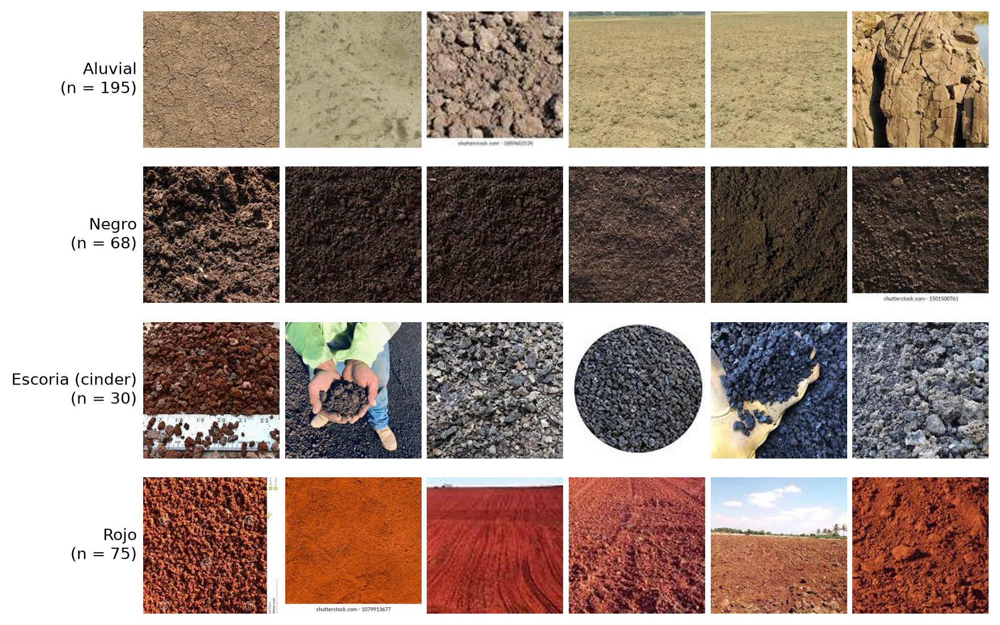

In [3]:
from src import visualizacion as vis
SALIDAS.mkdir(exist_ok=True)
vis.muestras_por_clase(exp.imagenes, exp.y, SALIDAS / "fig01_muestras.png")
figura("fig01_muestras.png", 760)

A simple vista, **el color es la pista más fuerte**: el suelo rojo es rojo, el
negro es oscuro, el aluvial es beige. La textura también varía —la escoria se
ve como grava gruesa de alto contraste; el rojo, como polvo fino y liso—, pero
la variabilidad *dentro* de cada clase es enorme (montículos, primeros planos,
paisajes). La clase aluvial, además, se ve sospechosamente repetitiva: muchas
de sus imágenes son cuadros consecutivos de un mismo video de un campo arado.

## 3. Auditoría del conjunto: duplicados y fuga de información (P3)

Un clasificador sólo demuestra que *reconoce* suelo si se le evalúa con
imágenes que no ha visto. Si una imagen de prueba tiene una copia en
entrenamiento, acertarla es **memoria**, no reconocimiento. Se auditó el
conjunto en dos niveles:

* **Duplicados exactos**: misma huella MD5 de los bytes del archivo.
* **Casi duplicados (misma escena)**: se calcula una *huella perceptual* —la
  miniatura a color de 32×32 del recorte central, centrada y de norma
  unitaria— y la similitud coseno entre todas las parejas. Dos imágenes son la
  misma escena si su similitud supera $\tau=0.95$; los grupos son las
  **componentes conexas** de ese grafo (unión-búsqueda), para que la relación
  sea transitiva: si A≈B y B≈C, A, B y C van juntas aunque A y C difieran un
  poco más.

El umbral se fijó inspeccionando visualmente parejas en las franjas
0.96–0.975, 0.975–0.985 y 0.985–0.995: aun en la franja más baja, las parejas
son el mismo campo con la cámara apenas desplazada.

In [4]:
exp.auditar()
au = exp.resumen_auditoria()
print(json.dumps({k: v for k, v in au.items() if k != "por_clase"}, ensure_ascii=False, indent=1))

{
 "imagenes": 368,
 "grupos_duplicado_exacto": 21,
 "imagenes_en_duplicado_exacto": 42,
 "duplicados_exactos_entre_particiones": 13,
 "mediana_similitud_maxima": 0.9998264312744141,
 "umbral_escena": 0.95,
 "escenas": 177,
 "escena_mas_grande": 38,
 "escenas_por_clase": {
  "alluvial": 47,
  "black": 57,
  "cinder": 30,
  "red": 43
 },
 "grupos_mixtos": 0,
 "test_con_gemela_en_train": 50,
 "imagenes_test": 73
}


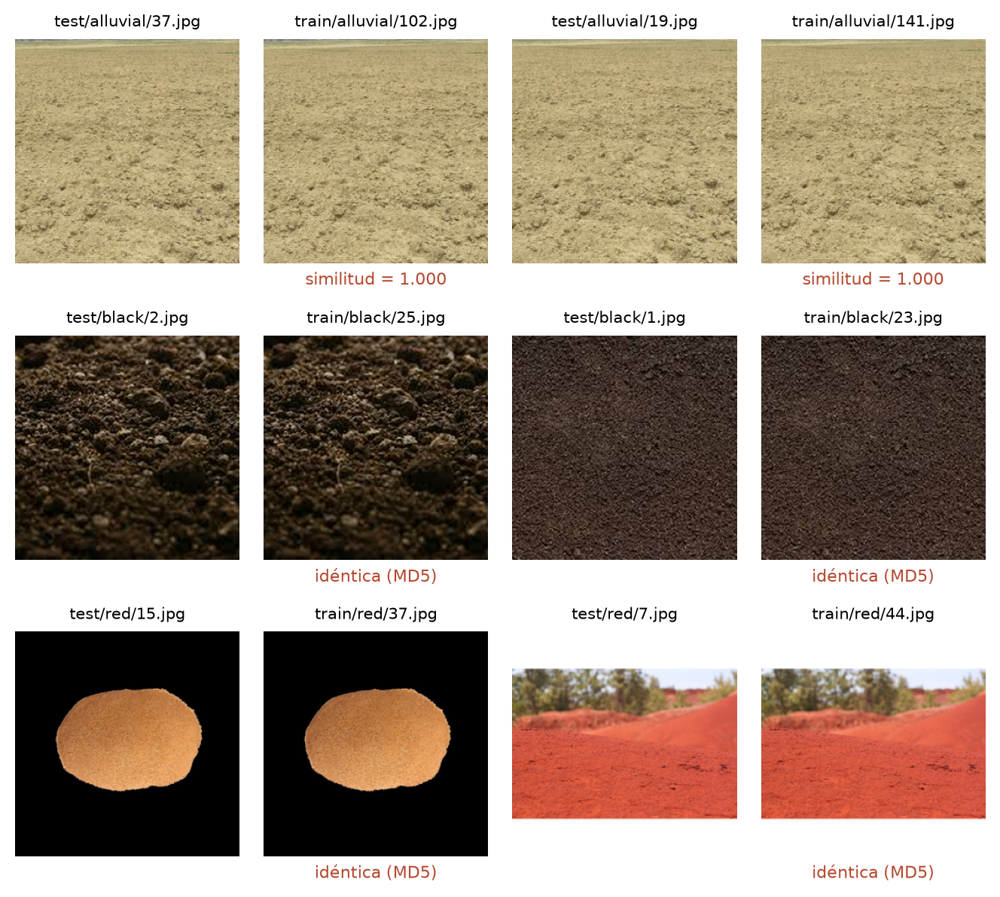

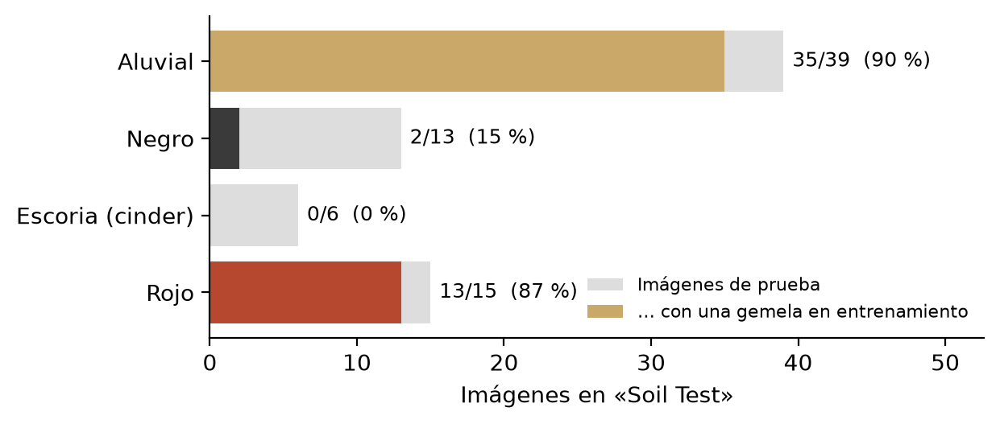

In [5]:
exp.extraer()                # matrices de características (se detallan en las secciones 4 y 5)
_ = exp.figuras_datos()      # figuras 1–9
figura("fig02_pares_fuga.png", 700)
figura("fig03_fuga_por_clase.png", 620)

**Diagnóstico.** La mitad de las imágenes tiene un gemelo casi idéntico
(la mediana de la similitud máxima de cada imagen con otra es ≈ 1.0), y
**dos de cada tres imágenes de `Soil Test` comparten escena con alguna de
`Soil Train`** —en las clases aluvial, negro y rojo; ninguna escoria—. La
partición original, por tanto, **sobreestima** el desempeño. Las 368 imágenes
se reducen a 177 escenas independientes, y ese es el «tamaño de muestra»
efectivo del problema.

**Consecuencia metodológica.** El resultado principal se mide con
**validación cruzada anidada estratificada por grupos** (sección 6): cada
escena entera cae en entrenamiento *o* en prueba, nunca en ambos. La partición
original se conserva como referencia y se desglosa en imágenes «con gemela» y
«sin gemela» para cuantificar la inflación.

## 4. Experimento 1 — Con Haralick

### 4.1 La matriz de co-ocurrencia (GLCM)

Haralick, Shanmugam y Dinstein (1973) propusieron describir la textura por la
**estadística de segundo orden** de los niveles de gris: no cuánto hay de cada
nivel (eso lo dice el histograma) sino **cómo se acompañan** los niveles a una
distancia y dirección dadas. Para un desplazamiento $(\Delta y,\Delta x)$, la
GLCM cuenta cuántas veces un píxel de nivel $i$ tiene a ese desplazamiento un
vecino de nivel $j$:

$$
C(i,j)=\#\{(y,x)\;:\;I(y,x)=i,\;I(y+\Delta y,\,x+\Delta x)=j\},\qquad
P=\frac{C+C^{\top}}{\sum (C+C^{\top})}.
$$

Sumar la transpuesta la vuelve **simétrica** (el par se cuenta en ambos
sentidos) y dividir entre el total la vuelve una distribución de probabilidad.
La forma de $P$ resume la textura:

* una textura **lisa** concentra la masa en la **diagonal** ($i\approx j$:
  vecinos parecidos);
* una textura **rugosa o de alto contraste** la dispersa lejos de la diagonal;
* una textura **regular** concentra la masa en pocas celdas (alta energía).

### 4.2 Decisiones de diseño

| Parámetro | Valor | Justificación |
|---|---|---|
| Canal | luminancia $Y$ (gris) y, como variante, $L^*$, $a^*$, $b^*$ de CIE-Lab | la textura clásica se mide en gris; Lab separa luminancia de cromaticidad para la variante a color |
| Niveles $L$ | 32 (cuantización uniforme) | con 256 niveles la GLCM tendría 65 536 celdas para ~65 000 pares de píxeles: casi vacía y ruidosa |
| Distancias $d$ | 1, 2, 4 y 8 px | la textura del suelo existe a varias escalas: grano fino (1–2 px) y terrón o grava (4–8 px) |
| Direcciones | 0°, 45°, 90°, 135° | las cuatro orientaciones no redundantes de la vecindad 8 |
| Resumen por dirección | **media** y **rango** (máx − mín) | lo propone Haralick: la media da invariancia aproximada a la rotación; el rango conserva cuánto *depende* de la orientación |

Resultado: $13\text{ rasgos}\times 2\text{ (media, rango)}\times 4\text{ distancias}=104$
rasgos en gris, y $3\times104=312$ en Lab.

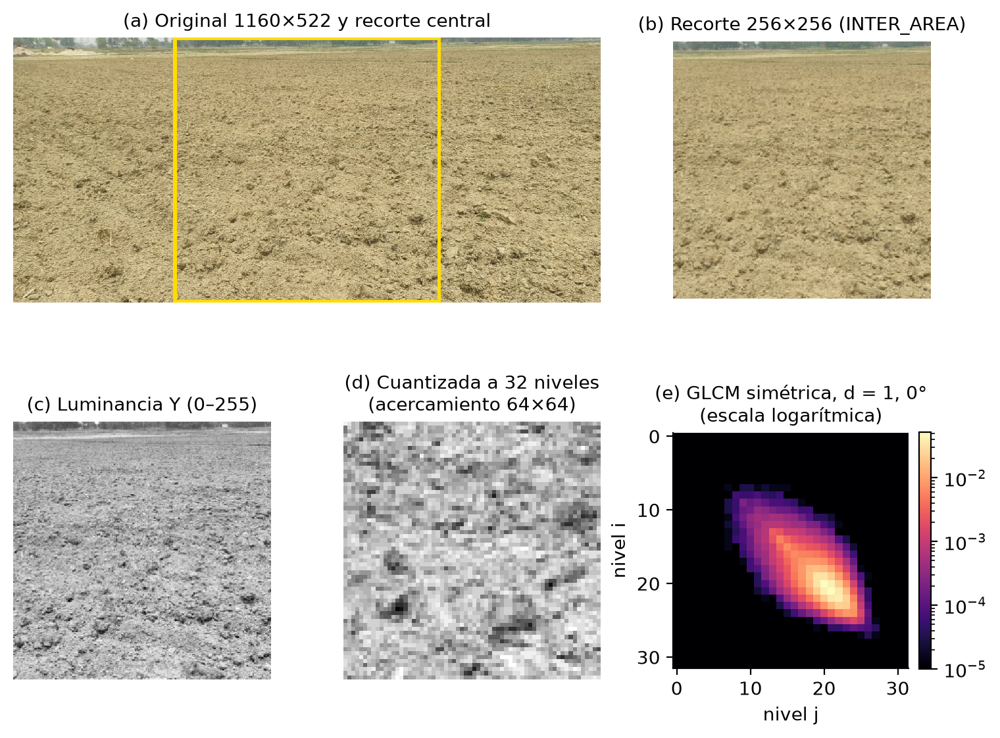

In [6]:
figura("fig04_pipeline_haralick.png", 980)

### 4.3 Los 13 descriptores

Con las marginales $p_x(i)=\sum_j P(i,j)$, $p_y(j)=\sum_i P(i,j)$ y las
distribuciones de suma y diferencia
$p_{x+y}(k)=\sum_{i+j=k}P(i,j)$, $p_{x-y}(k)=\sum_{|i-j|=k}P(i,j)$:

| # | Descriptor | Fórmula | Lectura |
|---|---|---|---|
| f1 | Energía (ASM) | $\sum_{i,j}P(i,j)^2$ | uniformidad: alta si pocas combinaciones dominan |
| f2 | Contraste | $\sum_k k^2\,p_{x-y}(k)$ | variación local; crece con la rugosidad |
| f3 | Correlación | $\frac{\sum_{i,j} ij\,P(i,j)-\mu_x\mu_y}{\sigma_x\sigma_y}$ | dependencia lineal entre vecinos |
| f4 | Varianza | $\sum_i (i-\mu_x)^2 p_x(i)$ | dispersión de niveles |
| f5 | Homogeneidad (IDM) | $\sum_{i,j}\frac{P(i,j)}{1+(i-j)^2}$ | cercanía a la diagonal; opuesta al contraste |
| f6 | Promedio de la suma | $\sum_k k\,p_{x+y}(k)$ | ≈ el doble del brillo medio |
| f7 | Varianza de la suma | $\sum_k (k-f_6)^2 p_{x+y}(k)$ | dispersión de la suma |
| f8 | Entropía de la suma | $-\sum_k p_{x+y}\log_2 p_{x+y}$ | desorden de la suma |
| f9 | Entropía | $-\sum_{i,j}P\log_2 P$ | complejidad/aleatoriedad de la textura |
| f10 | Varianza de la diferencia | $\mathrm{Var}[p_{x-y}]$ | dispersión del contraste local |
| f11 | Entropía de la diferencia | $-\sum_k p_{x-y}\log_2 p_{x-y}$ | desorden del contraste local |
| f12 | Info. de correlación 1 | $\frac{f_9-H_{XY1}}{\max(H_X,H_Y)}$ | dependencia medida con información mutua |
| f13 | Info. de correlación 2 | $\sqrt{1-e^{-2(H_{XY2}-f_9)}}$ | ídem, acotada en [0, 1] |

con $H_{XY1}=-\sum P\log_2(p_xp_y)$ y $H_{XY2}=-\sum p_xp_y\log_2(p_xp_y)$. Dos
precisiones respecto del artículo original: la f7 usa $f_6$ (el artículo
escribe $f_8$, una errata conocida), y la f10 es la varianza de la
*distribución* $p_{x-y}$.

### 4.4 Validación de la implementación

La GLCM y los 13 descriptores se implementaron en NumPy (`src/haralick.py`):
la GLCM se construye con un solo `np.bincount` sobre el índice lineal
$a\cdot L+b$ de los pares de píxeles, sin bucles. Para garantizar que las
fórmulas son correctas se comparan contra la biblioteca de referencia
**mahotas** (Coelho, 2013) en texturas sintéticas, tres semillas y tres
distancias. mahotas recorre las direcciones (0,1), (1,1), (1,0), (1,−1); con
GLCM simétrica equivalen a nuestras 0°, 135°, 90° y 45°.

In [7]:
rng = np.random.default_rng(0)
errores = []
for semilla in range(3):
    base = np.random.default_rng(semilla).normal(size=(96, 96)).cumsum(axis=1)
    base = (255 * (base - base.min()) / np.ptp(base)).astype(np.uint8)
    q = cuantizar(base, 32); niveles = int(q.max()) + 1
    for d in (1, 2, 4):
        propio = haralick_direcciones(q, niveles, d)
        ref = mahotas.features.haralick(q.astype(np.uint8), distance=d, use_x_minus_y_variance=True)[[0, 3, 2, 1]]
        errores.append(np.max(np.abs(propio - ref) / (np.abs(ref) + 1e-12)))
print(f"Error relativo máximo frente a mahotas en 9 casos × 4 direcciones × 13 rasgos: {max(errores):.1e}")

Error relativo máximo frente a mahotas en 9 casos × 4 direcciones × 13 rasgos: 6.8e-13


Las dos implementaciones coinciden hasta la precisión de máquina. La suite
`tests/test_haralick.py` repite esta comprobación con `pytest`.

### 4.5 Extracción y primera mirada a los descriptores

In [8]:
for nombre, X in exp.X.items():
    print(f"{nombre:18s} → matriz {X.shape[0]} × {X.shape[1]}   ({exp.tiempos['extraccion::' + nombre]:.1f} s)")

Haralick · gris    → matriz 368 × 104   (0.7 s)
Haralick · Lab     → matriz 368 × 312   (3.2 s)
Píxeles · gris     → matriz 368 × 1024   (0.0 s)
Píxeles · color    → matriz 368 × 3072   (0.0 s)


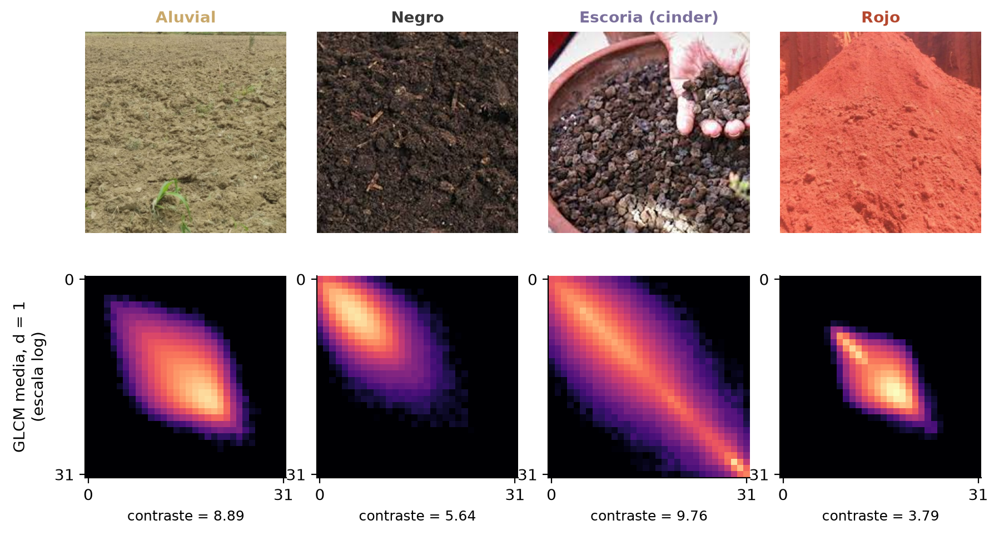

In [9]:
figura("fig05_glcm_por_clase.png", 860)

La GLCM ya separa visualmente las clases. En el **suelo negro** la masa se
concentra en los niveles bajos (oscuro) y cerca de la diagonal; en el **rojo**,
en una mancha compacta de niveles medios, con poco contraste: es un polvo fino
y liso. La **escoria** extiende la masa a lo largo de toda la diagonal y lejos
de ella —granos claros y oscuros alternados—, con el contraste más alto. El
**aluvial** ocupa niveles altos (claro) con una dispersión intermedia.

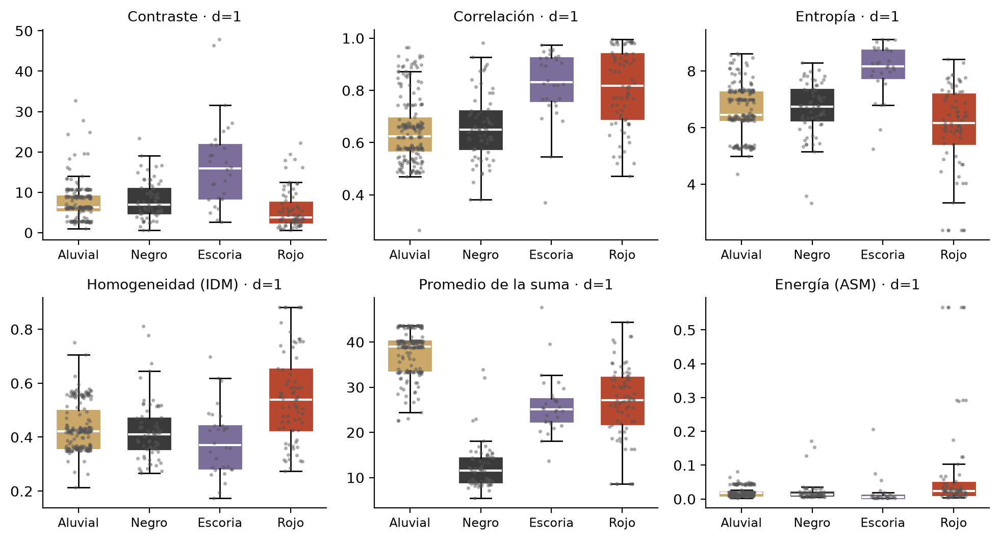

In [10]:
figura("fig06_cajas_haralick.png", 860)

Los diagramas de caja confirman la lectura con las 368 imágenes. Dos patrones
importan para lo que sigue:

* El **promedio de la suma** (f6), que es esencialmente el brillo medio,
  separa muy bien el suelo negro del resto: la GLCM en gris *no* es pura
  textura, arrastra también la intensidad.
* La **escoria** se distingue por **contraste y entropía altos**, y el **rojo**
  por **homogeneidad alta**: aquí sí habla la textura.

Ningún descriptor aislado separa las cuatro clases; la combinación de los 104
(o 312) es tarea del clasificador.

## 5. Experimento 2 — Sin Haralick: los píxeles como características

La alternativa es no diseñar descriptores: tomar la imagen normalizada,
reducirla a $32\times32$ (otra vez por área) y **aplanar** sus valores en un
vector $\mathbf{x}\in[0,1]^{3072}$ a color ($32\cdot32\cdot3$) o
$[0,1]^{1024}$ en gris. Cada componente es el valor de un píxel en una
posición fija.

¿Por qué 32×32? Con 368 imágenes, un vector de 196 608 componentes (256×256×3)
sería absurdo: el clasificador vería casi sólo ruido. Reducir promedia
bloques de 8×8 y conserva el color y la distribución gruesa de brillo, pero
**destruye la textura fina** —un píxel de la imagen reducida resume 64 del
original—. Es la representación «ingenua» clásica, y su debilidad de fondo es
que **no es invariante a la traslación**: la componente $k$ compara el mismo
lugar de dos imágenes, aunque el contenido esté en otro sitio.

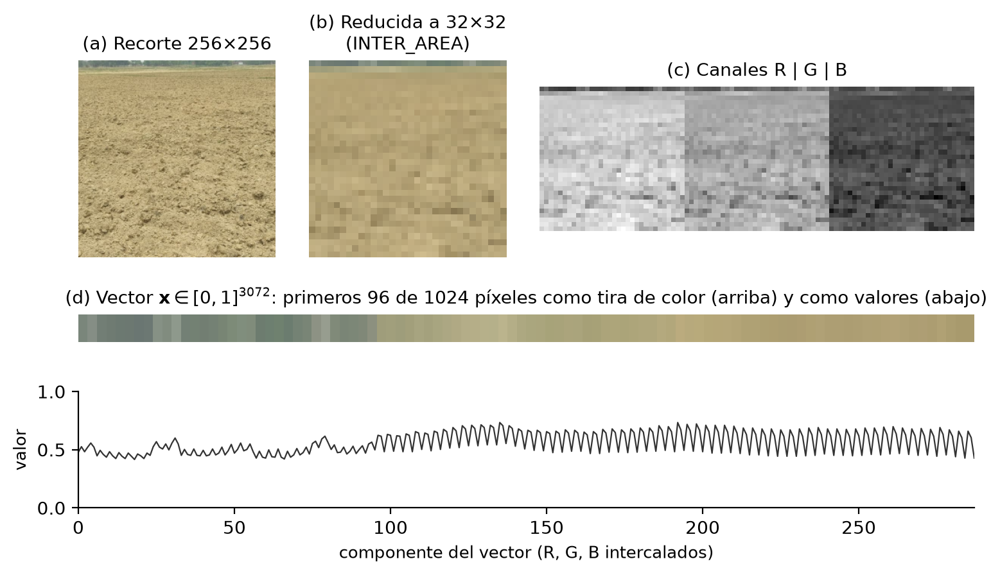

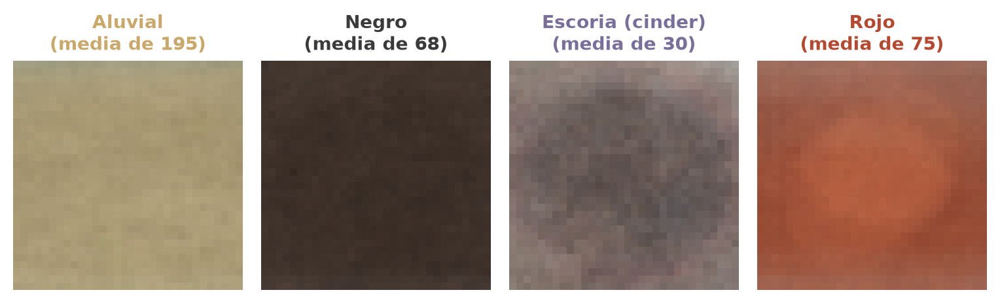

In [11]:
figura("fig07_pipeline_pixeles.png", 980)
figura("fig08_imagenes_medias.png", 760)

Las **imágenes medias por clase** muestran lo que «ve» la representación de
píxeles: un color de fondo por clase —beige, café oscuro, gris violáceo, rojo
ladrillo—, más un degradado vertical en la aluvial (cielo arriba en las
fotografías del campo). La información útil de los píxeles es,
sobre todo, **color**.

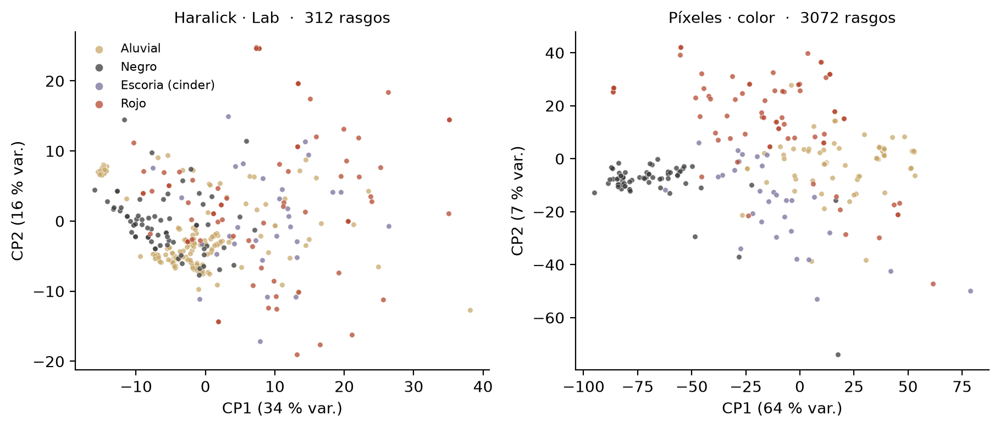

In [12]:
figura("fig09_pca.png", 900)

La proyección en las dos primeras componentes principales —sin usar
etiquetas— ya agrupa las clases en ambos espacios, con traslape entre escoria,
negro y aluvial. Dos componentes explican poco de la varianza; el clasificador
trabajará en el espacio completo.

## 6. Protocolo de evaluación

**Clasificadores.** Tres familias con supuestos distintos, todas dentro de un
`Pipeline` con `StandardScaler` (la estandarización se ajusta *sólo* con el
entrenamiento de cada pliegue):

| Clasificador | Rejilla de hiperparámetros |
|---|---|
| k-NN | $k\in\{1,3,5,7,9\}$, pesos uniformes o por distancia |
| SVM, kernel RBF, pesos de clase balanceados | $C\in\{0.1,1,10,100\}$, $\gamma\in\{\text{scale},10^{-3},10^{-2},10^{-1}\}$ |
| Bosque aleatorio (200 árboles, pesos balanceados) | rasgos por división ∈ {√p, 0.2p}, hoja mínima ∈ {1, 3} |

**Protocolo B (principal): validación cruzada anidada estratificada por
grupos.** El bucle externo (`StratifiedGroupKFold`, 5 pliegues, 3
repeticiones con barajado distinto = 15 estimaciones) mide el desempeño; dentro
de cada pliegue de entrenamiento, un bucle interno de 3 pliegues —también por
grupos— elige los hiperparámetros por F1 macro. Así la elección de
hiperparámetros nunca ve los datos con que se evalúa.

**Protocolo A (referencia): partición original**, `Soil Train` → `Soil Test`,
con los hiperparámetros elegidos por CV agrupada dentro de `Soil Train`.

**Control: CV anidada *sin* grupos**, idéntica a B pero repartiendo imágenes
sueltas al azar, para medir cuánto infla la fuga *dentro* de una validación
cruzada.

**Línea base:** un clasificador que siempre predice la clase mayoritaria.

In [13]:
exp.evaluar()
_ = exp.figuras_resultados()   # figuras 10–15
base = exp.cv["Clase mayoritaria"].resumen()
print(f"Línea base (clase mayoritaria): exactitud {base['exactitud']:.3f} · F1 macro {base['f1_macro']:.3f}")

Línea base (clase mayoritaria): exactitud 0.530 · F1 macro 0.173


## 7. Resultados

### 7.1 Comparación principal (P1 y P2)

In [14]:
filas = []
for f in exp.tabla_cv():
    filas.append({
        "Representación": f["representacion"], "Rasgos": f["rasgos"], "Clasificador": f["modelo"],
        "F1 macro": f"{f['f1_macro']:.3f} ± {f['f1_macro_de']:.3f}",
        "Exactitud": f"{f['exactitud']:.3f} ± {f['exactitud_de']:.3f}",
        "Exact. balanceada": f"{f['exactitud_balanceada']:.3f}",
        "Hiperparámetros más elegidos": f["hiperparametros_frecuentes"],
    })
tabla(filas, list(filas[0]))

| Representación | Rasgos | Clasificador | F1 macro | Exactitud | Exact. balanceada | Hiperparámetros más elegidos |
|---|---|---|---|---|---|---|
| Haralick · gris | 104 | k-NN | 0.697 ± 0.057 | 0.776 ± 0.044 | 0.694 | n_neighbors=1, weights=uniform (7/15) |
| Haralick · gris | 104 | SVM-RBF | 0.790 ± 0.054 | 0.844 ± 0.044 | 0.813 | C=10, gamma=0.001 (9/15) |
| Haralick · gris | 104 | Bosque aleatorio | 0.767 ± 0.086 | 0.785 ± 0.128 | 0.787 | max_features=0.2, min_samples_leaf=1 (4/15) |
| Haralick · Lab | 312 | k-NN | 0.828 ± 0.056 | 0.883 ± 0.042 | 0.833 | n_neighbors=5, weights=distance (9/15) |
| Haralick · Lab | 312 | SVM-RBF | 0.885 ± 0.040 | 0.931 ± 0.021 | 0.893 | C=100, gamma=0.001 (8/15) |
| Haralick · Lab | 312 | Bosque aleatorio | 0.887 ± 0.072 | 0.933 ± 0.039 | 0.898 | max_features=0.2, min_samples_leaf=3 (9/15) |
| Píxeles · gris | 1024 | k-NN | 0.628 ± 0.073 | 0.758 ± 0.096 | 0.647 | n_neighbors=1, weights=uniform (12/15) |
| Píxeles · gris | 1024 | SVM-RBF | 0.692 ± 0.091 | 0.750 ± 0.127 | 0.711 | C=1, gamma=scale (4/15) |
| Píxeles · gris | 1024 | Bosque aleatorio | 0.644 ± 0.091 | 0.758 ± 0.120 | 0.656 | max_features=0.2, min_samples_leaf=3 (5/15) |
| Píxeles · color | 3072 | k-NN | 0.819 ± 0.034 | 0.899 ± 0.021 | 0.807 | n_neighbors=1, weights=uniform (11/15) |
| Píxeles · color | 3072 | SVM-RBF | 0.898 ± 0.052 | 0.936 ± 0.032 | 0.911 | C=10, gamma=scale (11/15) |
| Píxeles · color | 3072 | Bosque aleatorio | 0.852 ± 0.048 | 0.905 ± 0.031 | 0.856 | max_features=sqrt, min_samples_leaf=3 (10/15) |

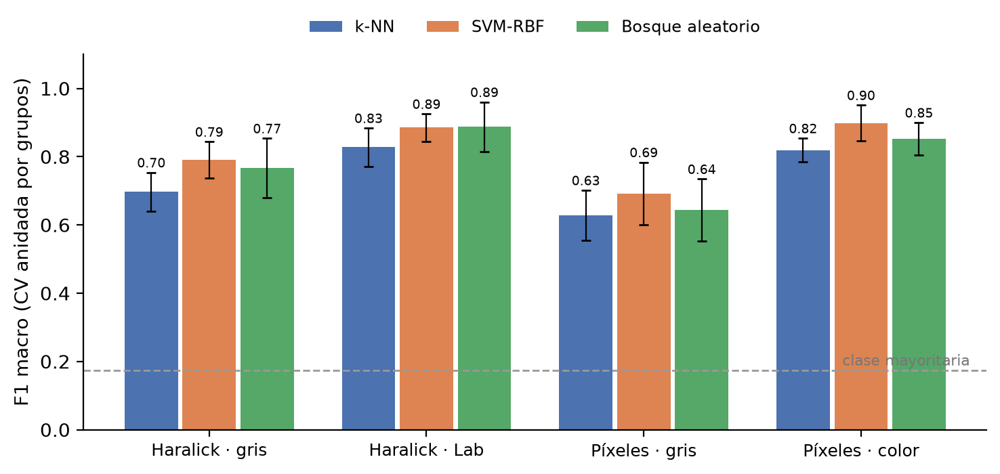

In [15]:
figura("fig10_resultados_f1.png", 900)

In [16]:
t = {(f["representacion"], f["modelo"]): f for f in exp.tabla_cv()}
mejor = lambda rep: max((v for (r, m), v in t.items() if r == rep), key=lambda v: v["f1_macro"])
for rep in REPRESENTACIONES:
    b = mejor(rep)
    print(f"{rep:18s} mejor: {b['modelo']:17s} F1 = {b['f1_macro']:.3f} ± {b['f1_macro_de']:.3f}")

Haralick · gris    mejor: SVM-RBF           F1 = 0.790 ± 0.054
Haralick · Lab     mejor: Bosque aleatorio  F1 = 0.887 ± 0.072
Píxeles · gris     mejor: SVM-RBF           F1 = 0.692 ± 0.091
Píxeles · color    mejor: SVM-RBF           F1 = 0.898 ± 0.052


**Lectura del diseño 2×2.**

* **En gris —donde sólo queda textura e intensidad— Haralick gana con
  claridad**: su mejor modelo (SVM-RBF, F1 ≈ 0.79) supera al mejor de píxeles
  en gris (SVM-RBF, F1 ≈ 0.69) por unos diez puntos, con desviaciones de 0.05–0.09.
  La GLCM resume la textura de forma *invariante a la posición*: le da igual
  dónde está cada terrón; los píxeles en gris, en cambio, comparan posición por
  posición y la textura fina desaparece al reducir a 32×32.
* **Con color, ambas representaciones empatan** en torno a F1 ≈ 0.89–0.90
  (Haralick·Lab con bosque o SVM; píxeles a color con SVM). La diferencia,
  ~0.01, es mucho menor que la variación entre pliegues (0.04–0.07): no es
  significativa con 177 escenas.
* **El color es el factor dominante (P2)**: añadirlo sube a Haralick unos 0.10
  de F1 y a los píxeles unos 0.21. Los píxeles dependen del color mucho más
  que Haralick, porque sin él no les queda casi nada útil.
* **El clasificador importa menos que la representación**: k-NN es siempre el
  peor —en estos espacios la distancia euclidiana en bruto es mala medida de
  parecido— y SVM-RBF es la mejor, o empata con la mejor, en las cuatro representaciones.

### 7.2 Efecto de la fuga (P3)

| Representación | Clasificador | Original: toda la prueba | Original: con gemela | Original: sin gemela | CV sin grupos | CV por grupos |
|---|---|---|---|---|---|---|
| Haralick · gris | k-NN | 0.890 | 1.000 | 0.652 | 0.813 | 0.776 |
| Haralick · gris | SVM-RBF | 0.918 | 1.000 | 0.739 | 0.852 | 0.844 |
| Haralick · gris | Bosque aleatorio | 0.945 | 1.000 | 0.826 | 0.878 | 0.785 |
| Haralick · Lab | k-NN | 0.918 | 1.000 | 0.739 | 0.899 | 0.883 |
| Haralick · Lab | SVM-RBF | 0.959 | 1.000 | 0.870 | 0.939 | 0.931 |
| Haralick · Lab | Bosque aleatorio | 0.959 | 1.000 | 0.870 | 0.939 | 0.933 |
| Píxeles · gris | k-NN | 0.877 | 1.000 | 0.609 | 0.822 | 0.758 |
| Píxeles · gris | SVM-RBF | 0.904 | 1.000 | 0.696 | 0.854 | 0.750 |
| Píxeles · gris | Bosque aleatorio | 0.904 | 1.000 | 0.696 | 0.842 | 0.758 |
| Píxeles · color | k-NN | 0.932 | 1.000 | 0.783 | 0.908 | 0.899 |
| Píxeles · color | SVM-RBF | 0.973 | 1.000 | 0.913 | 0.941 | 0.936 |
| Píxeles · color | Bosque aleatorio | 0.945 | 1.000 | 0.826 | 0.919 | 0.905 |

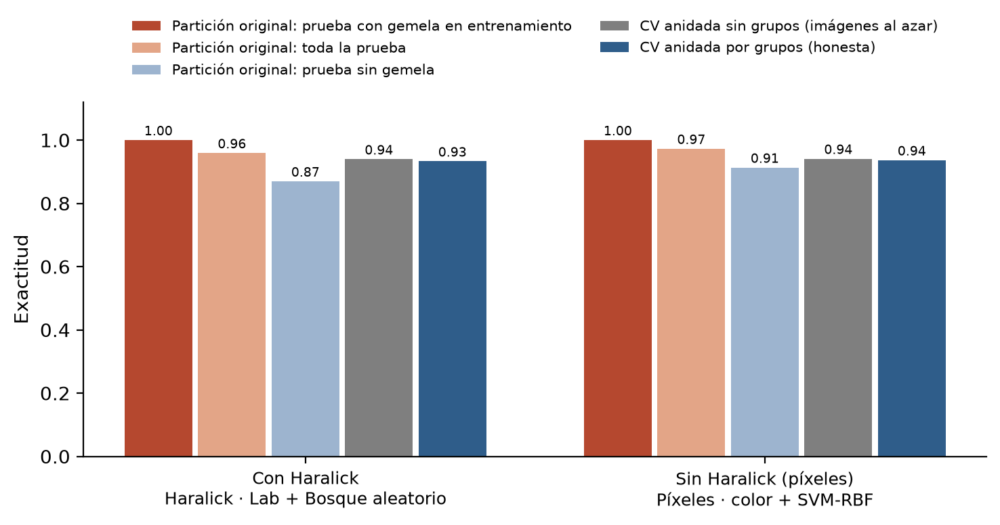

In [17]:
filas = []
for f in exp.tabla_cv():
    filas.append({
        "Representación": f["representacion"], "Clasificador": f["modelo"],
        "Original: toda la prueba": f"{f['orig_exactitud']:.3f}",
        "Original: con gemela": f"{f['orig_exactitud_contaminadas']:.3f}",
        "Original: sin gemela": f"{f['orig_exactitud_limpias']:.3f}",
        "CV sin grupos": f"{f['cv_sin_grupos_exactitud']:.3f}",
        "CV por grupos": f"{f['exactitud']:.3f}",
    })
tabla(filas, list(filas[0]))
figura("fig11_efecto_fuga.png", 880)

**La fuga es real y grande.** En las 50 imágenes de prueba con gemela en
entrenamiento, **todos los modelos aciertan el 100 %**, sea cual sea la
representación: es memoria. En las 23 sin gemela la exactitud cae hasta
0.61–0.91. Por eso la partición original reporta cifras infladas: hasta
0.973 de exactitud para píxeles a color con SVM, cuando la estimación honesta
es 0.936; y para Haralick en gris con k-NN, 0.890 frente a 0.776.

La **CV sin grupos** también infla, sobre todo en las representaciones
débiles (p. ej., píxeles en gris con SVM: 0.854 frente a 0.750 por grupos),
porque reparte cuadros del mismo video entre entrenamiento y prueba. Que k-NN
elija casi siempre $k=1$ —el vecino más cercano— es otro síntoma: con
gemelas en el conjunto, copiar al vecino es la estrategia ganadora.

### 7.3 Qué clases se confunden

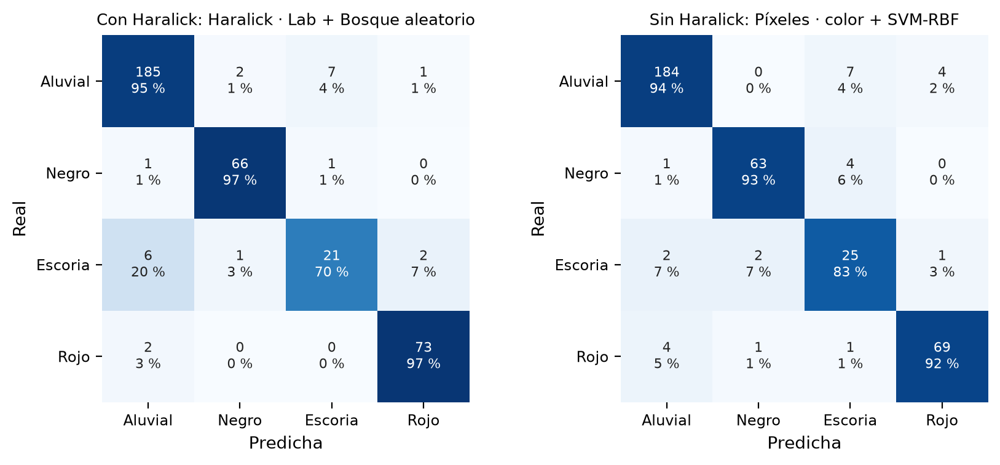


Haralick: Haralick · Lab + Bosque aleatorio (predicciones fuera de pliegue, 1.ª repetición)
                  precision    recall  f1-score   support

         Aluvial      0.954     0.949     0.951       195
           Negro      0.957     0.971     0.964        68
Escoria (cinder)      0.724     0.700     0.712        30
            Rojo      0.961     0.973     0.967        75

        accuracy                          0.938       368
       macro avg      0.899     0.898     0.898       368
    weighted avg      0.937     0.938     0.937       368


Píxeles: Píxeles · color + SVM-RBF (predicciones fuera de pliegue, 1.ª repetición)
                  precision    recall  f1-score   support

         Aluvial      0.963     0.944     0.953       195
           Negro      0.955     0.926     0.940        68
Escoria (cinder)      0.676     0.833     0.746        30
            Rojo      0.932     0.920     0.926        75

        accuracy                          0.927       368
      

In [18]:
figura("fig12_confusion.png", 880)
from sklearn.metrics import classification_report
for pref in ("Haralick", "Píxeles"):
    clave = exp.mejor(pref)
    print(f"\n{pref}: {clave[0]} + {clave[1]} (predicciones fuera de pliegue, 1.ª repetición)")
    print(classification_report(exp.y, exp.cv[clave].oof, target_names=[NOMBRES[c] for c in CLASES], digits=3))

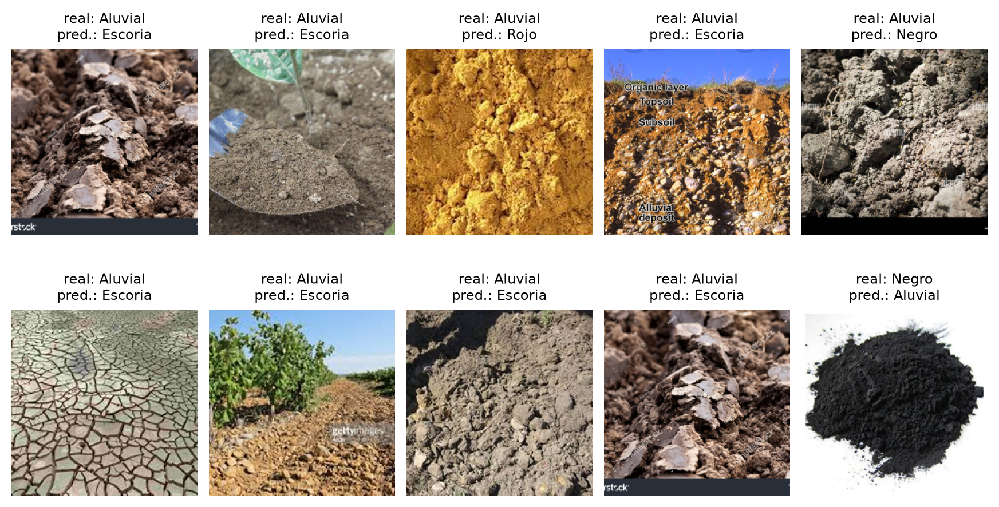

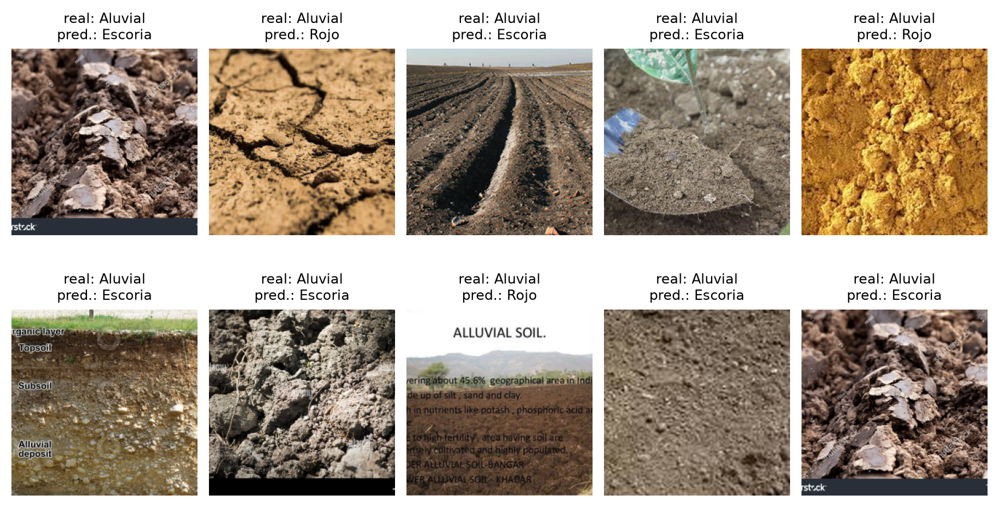

In [19]:
figura("fig13_errores_haralick.png", 760)
figura("fig14_errores_pixeles.png", 760)

**La clase difícil es la escoria** (F1 ≈ 0.71–0.75; las otras tres superan
0.92). Es la más pequeña (30 imágenes) y la más heterogénea: grava roja,
gris o negra, fotografiada en macetas, manos, bolsas y pilas. Haralick la
confunde sobre todo con **aluvial**: terrones claros y oscuros alternados
producen la misma GLCM de alto contraste que la grava. Los píxeles la
confunden menos con aluvial pero más con negro, porque una escoria oscura
tiene casi el mismo color medio que el suelo negro.

Los ejemplos mal clasificados muestran además **ruido del propio conjunto**:
un diagrama de horizontes con texto («Organic layer», «Topsoil»), viñedos con
cielo, suelo agrietado verdoso o polvo negro sobre fondo blanco. Son imágenes
de banco con marcas de agua que poco se parecen a una fotografía de campo.

### 7.4 Qué descriptores usa el bosque

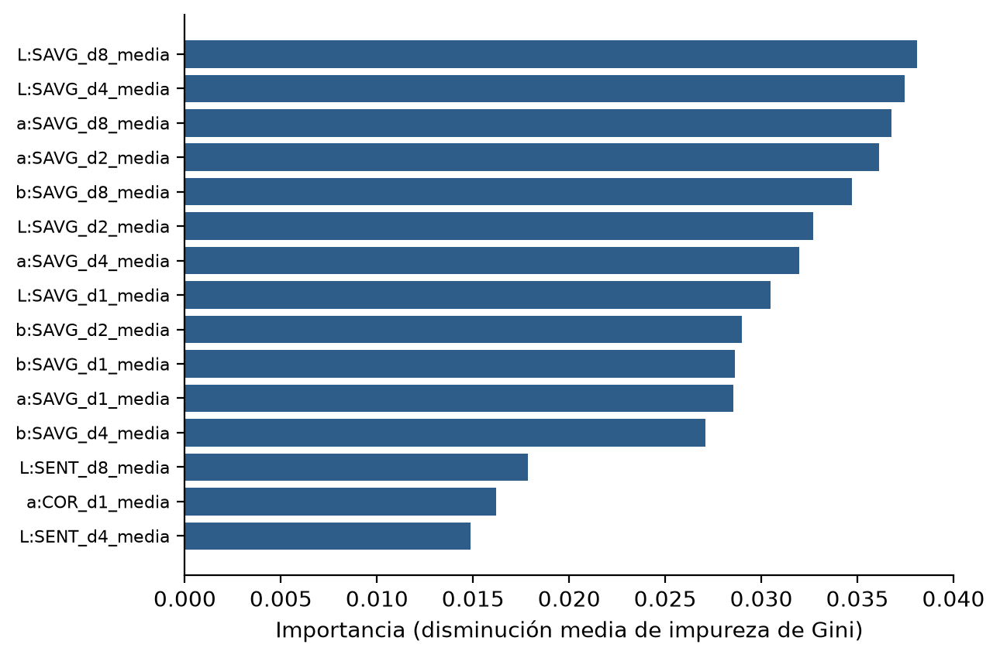

In [20]:
figura("fig15_importancias_haralick_lab.png", 640)

Las 12 variables más importantes del bosque son el **promedio de la suma**
(f6) de los canales $L^*$, $a^*$ y $b^*$ a las cuatro distancias. Como
$f_6\approx 2\,\bar I$, esas variables son, en la práctica, **el color medio
de la imagen en Lab**. Las de textura propiamente dicha (entropía de la suma,
correlación) aparecen después. Es la confirmación cuantitativa de P2: aun
dentro del descriptor de Haralick, lo que más discrimina el suelo es el color,
y la textura aporta como segundo criterio.

### 7.5 Sensibilidad a los parámetros de cada representación

Con SVM-RBF y el mismo protocolo B se varían la escala de la GLCM (sólo
$d=1$ frente a $d\in\{1,2,4,8\}$), el número de niveles de gris y la
resolución de la imagen de píxeles.

In [21]:
exp.ablaciones()
filas = [{"Variante": k, "Rasgos": v["rasgos"], "F1 macro": f"{v['f1_macro']:.3f} ± {v['f1_macro_de']:.3f}",
          "Exactitud": f"{v['exactitud']:.3f}"} for k, v in exp.ablacion.items()]
tabla(filas, list(filas[0]))

| Variante | Rasgos | F1 macro | Exactitud |
|---|---|---|---|
| Haralick · gris · d={1} | 26 | 0.713 ± 0.073 | 0.763 |
| Haralick · gris · d={1,2,4,8} · 16 niveles | 104 | 0.760 ± 0.095 | 0.825 |
| Haralick · gris · d={1,2,4,8} · 32 niveles | 104 | 0.790 ± 0.054 | 0.844 |
| Haralick · gris · d={1,2,4,8} · 64 niveles | 104 | 0.804 ± 0.043 | 0.857 |
| Píxeles · color 8×8 | 192 | 0.883 ± 0.047 | 0.933 |
| Píxeles · color 16×16 | 768 | 0.889 ± 0.038 | 0.930 |
| Píxeles · color 32×32 | 3072 | 0.898 ± 0.052 | 0.936 |
| Píxeles · color 64×64 | 12288 | 0.893 ± 0.045 | 0.927 |

* **Escala de la GLCM.** Usar sólo $d=1$ (26 rasgos) baja el F1 de 0.79 a
  0.71: la textura del suelo vive a varias escalas, y los terrones y la grava
  se ven a 4–8 px.
* **Niveles de gris.** 16 niveles pierden detalle (0.76); 32 y 64 rinden igual
  dentro de la variación (0.79–0.80).
* **Resolución de los píxeles.** De 8×8 (192 rasgos) a 64×64 (12 288) el F1
  apenas cambia (0.88–0.90). Una imagen de 8×8 ya no tiene textura; si rinde
  igual que una de 64×64, **lo que los píxeles aprovechan es el color**, no la
  forma ni la textura.

In [22]:
print("Resultados guardados en", exp.guardar_resultados())

Resultados guardados en /Users/victormanuel/Library/Mobile Documents/com~apple~CloudDocs/Maestría UMPH/Cuatrimestre 4/Sistemas de Visión Artificial/Actividades/Actividad 6/salidas/resultados.json


## 8. Conclusiones

1. **Haralick es mejor descriptor de textura que los píxeles.** Sin color, la
   GLCM multiescala supera a los píxeles por unos diez puntos de F1 macro
   (0.79 frente a 0.69), porque resume la estadística de vecindad sin depender
   de la posición.
2. **Con color, ambas llegan a F1 ≈ 0.89–0.90 y empatan**, porque en este
   conjunto **el color es el rasgo dominante**: el color medio en Lab
   encabeza la importancia del bosque, y los píxeles rinden igual a 8×8 que a
   64×64.
3. **La escoria volcánica es la clase difícil** (F1 ≈ 0.71–0.75), por pocos
   ejemplos y mucha variabilidad.
4. **El conjunto tiene fuga**: 50 de 73 imágenes de prueba tienen gemela en
   entrenamiento y se aciertan al 100 % siempre. Evaluar con la partición
   original sobreestima la exactitud hasta en 16 puntos (Haralick en gris con bosque: 0.945 frente a 0.785); la estimación honesta
   requiere agrupar por escena.

**Trabajo futuro.** Combinar descriptores de color (momentos o histogramas en
Lab) con la textura de Haralick, en lugar de pedirle a la GLCM que cargue con
el color; probar descriptores invariantes a escala (LBP multirresolución,
filtros de Gabor) o redes convolucionales preentrenadas como extractor; y,
sobre todo, un conjunto de fotografías de campo tomadas con protocolo
—distancia, iluminación, sin marcas de agua— y separado por sitio.

## Referencias

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Coelho, L. P. (2013). Mahotas: Open source software for scriptable computer vision. *Journal of Open Research Software, 1*(1), e3. https://doi.org/10.5334/jors.ac

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018

Haralick, R. M., Shanmugam, K., & Dinstein, I. (1973). Textural features for image classification. *IEEE Transactions on Systems, Man, and Cybernetics, SMC-3*(6), 610–621. https://doi.org/10.1109/TSMC.1973.4309314

Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91. https://doi.org/10.1186/1471-2105-7-91